In [165]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
import statsmodels.api as sm
import matplotlib.pyplot as plt

In [271]:
file_path = "/Users/hapham/Downloads/Industry_Mom_Spreadsheet.csv"
df = pd.read_csv(file_path, header=6)
df = df.drop(columns=['Unnamed: 3'])
df = df.rename(columns={df.columns[0]: 'Date'})
df.columns = df.columns.str.strip()
df

,Date,RF,Mkt-RF,Food,Beer,Smoke,Games,Books,Hshld,Clths,...,Telcm,Servs,BusEq,Paper,Trans,Whlsl,Rtail,Meals,Fin,Other
0,192607,0.22%,2.62%,0.53%,-5.19%,1.29%,2.30%,10.97%,-0.50%,8.08%,...,0.83%,9.22%,2.06%,7.66%,1.91%,-23.79%,-2.94%,1.83%,0.16%,5.20%
1,192608,0.25%,2.56%,2.71%,27.03%,6.53%,0.54%,10.01%,-3.58%,-2.51%,...,2.17%,2.02%,4.40%,-2.37%,4.87%,5.39%,-0.56%,-0.09%,4.38%,6.76%
2,192609,0.23%,0.36%,1.29%,4.02%,1.22%,5.92%,-0.99%,0.71%,-0.51%,...,2.41%,2.25%,0.18%,-5.55%,0.06%,-7.87%,0.17%,-0.58%,-1.36%,-3.86%
3,192610,0.32%,-3.43%,-3.13%,-3.31%,1.07%,-4.41%,9.47%,-4.66%,0.12%,...,-0.11%,-2.00%,-1.08%,-5.03%,-2.65%,-15.38%,-5.34%,-4.13%,-5.09%,-8.49%
4,192611,0.31%,2.44%,6.28%,7.29%,4.41%,2.60%,-5.80%,-0.51%,1.87%,...,1.63%,3.77%,3.64%,3.81%,1.59%,4.67%,4.04%,4.32%,2.29%,4.00%
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1009,201008,0.01%,-4.40%,-0.41%,-0.02%,-0.06%,-1.21%,-9.88%,-3.83%,-7.17%,...,-1.95%,-5.01%,-8.40%,-6.07%,-5.16%,-7.56%,-4.23%,0.49%,-8.43%,-4.17%
1010,201009,0.01%,9.24%,1.65%,4.94%,10.04%,14.31%,12.65%,3.80%,17.33%,...,7.94%,11.37%,13.64%,9.12%,10.21%,9.83%,13.69%,7.35%,7.23%,8.09%
1011,201010,0.01%,3.89%,5.81%,1.87%,5.28%,12.71%,7.33%,4.37%,3.54%,...,4.41%,7.71%,4.43%,3.52%,5.51%,4.97%,1.30%,6.02%,1.67%,-1.34%
1012,201011,0.01%,0.58%,-1.94%,1.96%,-3.79%,7.46%,-3.48%,-2.53%,8.98%,...,-1.93%,-2.22%,1.00%,0.28%,2.30%,0.25%,5.00%,4.16%,-0.26%,-0.44%


In [272]:
df['Date'] = pd.to_datetime(df['Date'].astype(str).str[:6], format='%Y%m', errors='coerce')
df = df.dropna(subset=['Date'])
df = df.set_index('Date')

In [273]:
for col in df.columns[1:]:
    df[col] = df[col].astype(str).str.replace('%','').astype(float)/100
df

,RF,Mkt-RF,Food,Beer,Smoke,Games,Books,Hshld,Clths,Hlth,...,Telcm,Servs,BusEq,Paper,Trans,Whlsl,Rtail,Meals,Fin,Other
Date,,,,,,,,,,,,,,,,,,,,,
1926-07-01,0.22%,0.0262,0.0053,-0.0519,0.0129,0.0230,0.1097,-0.0050,0.0808,0.0164,...,0.0083,0.0922,0.0206,0.0766,0.0191,-0.2379,-0.0294,0.0183,0.0016,0.0520
1926-08-01,0.25%,0.0256,0.0271,0.2703,0.0653,0.0054,0.1001,-0.0358,-0.0251,0.0451,...,0.0217,0.0202,0.0440,-0.0237,0.0487,0.0539,-0.0056,-0.0009,0.0438,0.0676
1926-09-01,0.23%,0.0036,0.0129,0.0402,0.0122,0.0592,-0.0099,0.0071,-0.0051,0.0061,...,0.0241,0.0225,0.0018,-0.0555,0.0006,-0.0787,0.0017,-0.0058,-0.0136,-0.0386
1926-10-01,0.32%,-0.0343,-0.0313,-0.0331,0.0107,-0.0441,0.0947,-0.0466,0.0012,-0.0073,...,-0.0011,-0.0200,-0.0108,-0.0503,-0.0265,-0.1538,-0.0534,-0.0413,-0.0509,-0.0849
1926-11-01,0.31%,0.0244,0.0628,0.0729,0.0441,0.0260,-0.0580,-0.0051,0.0187,0.0553,...,0.0163,0.0377,0.0364,0.0381,0.0159,0.0467,0.0404,0.0432,0.0229,0.0400
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2010-08-01,0.01%,-0.0440,-0.0041,-0.0002,-0.0006,-0.0121,-0.0988,-0.0383,-0.0717,-0.0162,...,-0.0195,-0.0501,-0.0840,-0.0607,-0.0516,-0.0756,-0.0423,0.0049,-0.0843,-0.0417
2010-09-01,0.01%,0.0924,0.0165,0.0494,0.1004,0.1431,0.1265,0.0380,0.1733,0.0904,...,0.0794,0.1137,0.1364,0.0912,0.1021,0.0983,0.1369,0.0735,0.0723,0.0809
2010-10-01,0.01%,0.0389,0.0581,0.0187,0.0528,0.1271,0.0733,0.0437,0.0354,0.0193,...,0.0441,0.0771,0.0443,0.0352,0.0551,0.0497,0.0130,0.0602,0.0167,-0.0134


In [293]:
industries = [c for c in df.columns if c not in ['RF', 'Mkt-RF']]
df_industry = df[industries].copy()

In [294]:
df_avg12 = (df_industry.rolling(window=12, min_periods=12).mean().shift(1))
df_avg12.head(13)

,Food,Beer,Smoke,Games,Books,Hshld,Clths,Hlth,Chems,Txtls,...,Telcm,Servs,BusEq,Paper,Trans,Whlsl,Rtail,Meals,Fin,Other
Date,,,,,,,,,,,,,,,,,,,,,
1926-07-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1926-08-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1926-09-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1926-10-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1926-11-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1926-12-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1927-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1927-02-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1927-03-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [295]:
# For each month, rank the industry
ranks = df_avg12.rank(axis = 1, method = 'average')
ranks

,Food,Beer,Smoke,Games,Books,Hshld,Clths,Hlth,Chems,Txtls,...,Telcm,Servs,BusEq,Paper,Trans,Whlsl,Rtail,Meals,Fin,Other
Date,,,,,,,,,,,,,,,,,,,,,
1926-07-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1926-08-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1926-09-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1926-10-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1926-11-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2010-08-01,4.0,11.0,18.0,29.0,15.0,10.0,26.0,2.0,19.0,13.0,...,20.0,9.0,12.0,16.0,24.0,17.0,7.0,25.0,8.0,14.0
2010-09-01,10.0,18.0,24.0,30.0,6.0,16.0,20.0,5.0,25.0,15.0,...,26.0,8.0,9.0,14.0,22.0,11.0,7.0,28.0,1.0,12.0
2010-10-01,6.0,12.0,24.0,29.0,11.0,7.0,20.0,5.0,22.0,19.0,...,21.0,10.0,14.0,16.0,26.0,15.0,13.0,28.0,1.0,8.0


In [296]:
#Compute each industry average rank
avg_rank = ranks.mean().sort_values()
avg_rank

Telcm    14.088323
Other    14.216068
Clths    14.540918
Util     14.767465
Whlsl    14.773453
Steel    14.890220
Cnstr    14.908184
Hshld    14.943114
Mines    14.957086
Books    14.974052
Trans    14.999002
Food     15.183633
Txtls    15.238523
Rtail    15.381737
Chems    15.488024
Paper    15.507984
Hlth     15.657186
FabPr    15.761477
Fin      15.802395
Oil      15.910679
Meals    15.951098
Coal     16.004990
Autos    16.013473
BusEq    16.093812
Smoke    16.216567
Games    16.247505
Beer     16.386228
Servs    16.410679
Carry    16.518463
ElcEq    17.167665
dtype: float64

In [297]:
# • Which industry has the lowest average rank and which has the highest?
# • What is the average rank of these lowest and highest industries?
lowest_industry  = avg_rank.idxmin()
highest_industry = avg_rank.idxmax()
lowest_value  = avg_rank.min()
highest_value = avg_rank.max()

print(f"• Industry with the lowest average rank: {lowest_industry} with lowest value is {lowest_value:.6f}")
print(f"• Industry with the highest average rank: {highest_industry} with lowest value is {highest_value:.6f}")

• Industry with the lowest average rank: Telcm with lowest value is 14.088323
• Industry with the highest average rank: ElcEq with lowest value is 17.167665


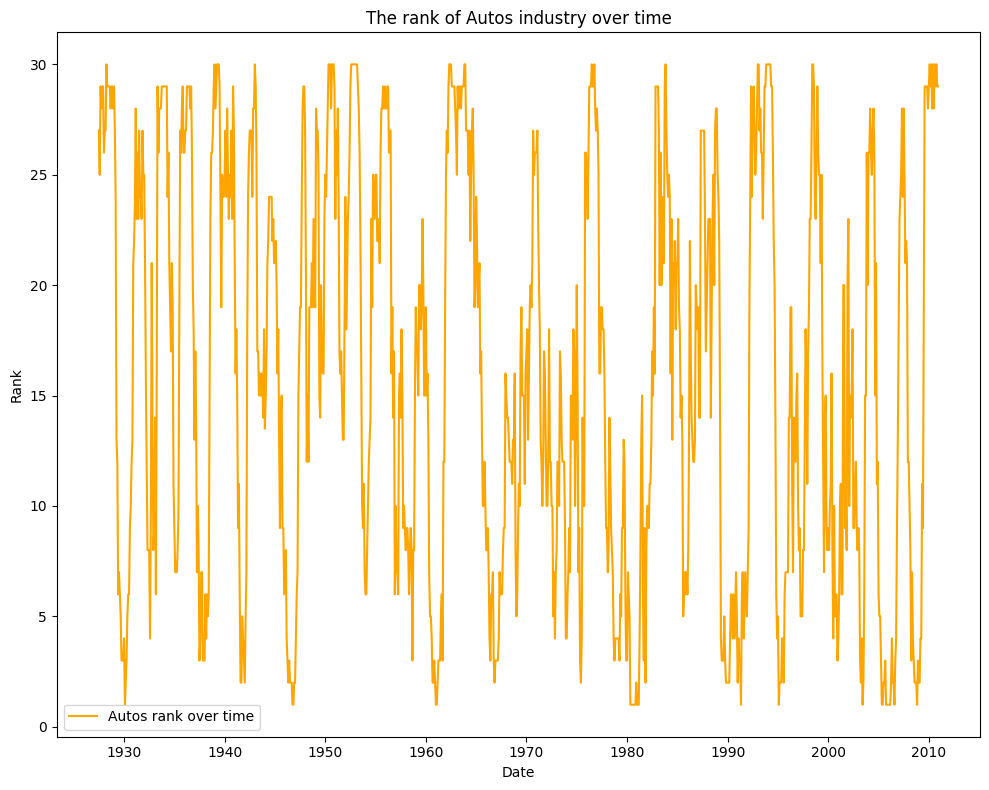

In [298]:
# Plot of the rank of Autos industry over time.
plt.figure(figsize = (10,8))
plt.plot(ranks.index, ranks['Autos'], color = 'orange', label = 'Autos rank over time')
plt.title("The rank of Autos industry over time")
plt.xlabel("Date")
plt.ylabel("Rank")
plt.legend()
plt.tight_layout()
plt.show()

In [299]:
rank_volatility = ranks.std().sort_values()
rank_volatility

Cnstr     6.305061
Other     7.221656
FabPr     7.234857
Fin       7.379188
Rtail     7.474982
Paper     7.484679
Food      7.490501
Chems     7.543703
ElcEq     7.663361
Hshld     7.914330
Whlsl     8.128069
Trans     8.212889
Util      8.504733
BusEq     8.613738
Clths     8.617689
Meals     8.695573
Books     8.910776
Hlth      8.926915
Carry     9.069986
Telcm     9.074860
Oil       9.078922
Servs     9.243798
Beer      9.355640
Autos     9.396370
Steel     9.490935
Txtls     9.566320
Mines     9.586931
Games     9.681678
Smoke     9.822806
Coal     11.318254
dtype: float64

In [300]:
#Are the top industries stable or moving around a lot? 
# I.e., is industry momentum a long-term bet on a few industries or a very dynamic strategy? 
# Do you expect high or low turnover from this strategy?

# Yes. The top industry move around a lot. I would expect this strategy is high turnover based on the 
# volitility of the top industry

In [301]:
# 2.2 Winner portfolio

In [302]:
#15 winner industries
winner_15 = df_avg12.rank(axis=1, ascending=False) <= 15
winner_15

,Food,Beer,Smoke,Games,Books,Hshld,Clths,Hlth,Chems,Txtls,...,Telcm,Servs,BusEq,Paper,Trans,Whlsl,Rtail,Meals,Fin,Other
Date,,,,,,,,,,,,,,,,,,,,,
1926-07-01,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1926-08-01,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1926-09-01,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1926-10-01,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1926-11-01,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2010-08-01,False,False,True,True,False,False,True,False,True,False,...,True,False,False,True,True,True,False,True,False,False
2010-09-01,False,True,True,True,False,True,True,False,True,False,...,True,False,False,False,True,False,False,True,False,False
2010-10-01,False,False,True,True,False,False,True,False,True,True,...,True,False,False,True,True,False,False,True,False,False


In [308]:
# Compute average return of those winners
winner_returns = df_avg12.loc[winner_15.index] * winner_15
winner_portfolio = winner_returns.mean(axis=1).dropna()
winner_portfolio

Date
1927-07-01    0.014358
1927-08-01    0.015955
1927-09-01    0.014889
1927-10-01    0.016414
1927-11-01    0.016636
                ...   
2010-08-01    0.012384
2010-09-01    0.009329
2010-10-01    0.011302
2010-11-01    0.015293
2010-12-01    0.013672
Length: 1002, dtype: float64

In [340]:
# Ensure RF column is clean and numeric
df.columns = df.columns.str.strip()   # remove stray spaces
df['RF'] = df['RF'].astype(str).str.replace('%','').astype(float) / 100

rf = df['RF'].copy()
rf.index = pd.to_datetime(df.index)

In [353]:
common_idx = winner_portfolio.index.intersection(rf.index)
rf = rf.loc[common_idx]
winner_portfolio = winner_portfolio.loc[common_idx]
winner_excess = (winner_portfolio - rf).dropna()

In [354]:
mean_monthly = winner_excess.mean()
std_monthly = winner_excess.std()
sharpe_monthly = mean_monthly / std_monthly
sharpe_annual = sharpe_monthly * np.sqrt(12)

In [356]:
print(f"Average monthly excess return: {mean_monthly:.3%}")
print(f"Standard deviation: {std_monthly:.3%}")
print(f"Monthly Sharpe ratio: {sharpe_monthly:.3f}")
print(f"Annualized Sharpe ratio: {sharpe_annual:.3f}")

Average monthly excess return: 0.973%
Standard deviation: 0.902%
Monthly Sharpe ratio: 1.079
Annualized Sharpe ratio: 3.738


In [357]:
# 2.3. Loser portfolio

In [358]:
loser_15 = df_avg12.rank(axis=1, ascending=True) <= 15
loser_15

,Food,Beer,Smoke,Games,Books,Hshld,Clths,Hlth,Chems,Txtls,...,Telcm,Servs,BusEq,Paper,Trans,Whlsl,Rtail,Meals,Fin,Other
Date,,,,,,,,,,,,,,,,,,,,,
1926-07-01,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1926-08-01,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1926-09-01,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1926-10-01,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1926-11-01,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2010-08-01,True,True,False,False,True,True,False,True,False,True,...,False,True,True,False,False,False,True,False,True,True
2010-09-01,True,False,False,False,True,False,False,True,False,True,...,False,True,True,True,False,True,True,False,True,True
2010-10-01,True,True,False,False,True,True,False,True,False,False,...,False,True,True,False,False,True,True,False,True,True


In [359]:
loser_returns = df_avg12.loc[loser_15.index] * loser_15
loser_portfolio = loser_returns.mean(axis=1).dropna()
loser_portfolio

Date
1927-07-01    0.002090
1927-08-01    0.004422
1927-09-01    0.004698
1927-10-01    0.006781
1927-11-01    0.006726
                ...   
2010-08-01    0.005475
2010-09-01    0.002071
2010-10-01    0.004320
2010-11-01    0.006911
2010-12-01    0.004862
Length: 1002, dtype: float64

In [360]:
df.columns = df.columns.str.strip()   
df['RF'] = df['RF'].astype(str).str.replace('%','').astype(float) / 100

rf = df['RF'].copy()
rf.index = pd.to_datetime(df.index)

common_idx = loser_portfolio.index.intersection(rf.index)
rf = rf.loc[common_idx]
loser_portfolio = loser_portfolio.loc[common_idx]
loser_excess = (loser_portfolio - rf).dropna()

In [361]:
mean_monthly = loser_excess.mean()
std_monthly = loser_excess.std()
sharpe_monthly = mean_monthly / std_monthly
sharpe_annual = sharpe_monthly * np.sqrt(12)

In [362]:
print(f"Average monthly excess return: {mean_monthly:.3%}")
print(f"Standard deviation: {std_monthly:.3%}")
print(f"Monthly Sharpe ratio: {sharpe_monthly:.3f}")
print(f"Annualized Sharpe ratio: {sharpe_annual:.3f}")

Average monthly excess return: 0.037%
Standard deviation: 0.900%
Monthly Sharpe ratio: 0.041
Annualized Sharpe ratio: 0.142


In [363]:
# What is the annualized Sharpe ratio of the overall market index?
mkt = df['Mkt-RF']
mkt.index = pd.to_datetime(mkt.index)
shapre_annual_mkt = mkt.mean()/mkt.std()*np.sqrt(12)
shapre_annual_mkt

0.395816154977151

In [364]:
# 2.4.Long-short ind-mom

In [397]:
ind_mom = (winner_portfolio - loser_portfolio)
ind_mom 

Date
1927-07-01    0.012268
1927-08-01    0.011533
1927-09-01    0.010191
1927-10-01    0.009633
1927-11-01    0.009910
                ...   
2010-08-01    0.006909
2010-09-01    0.007258
2010-10-01    0.006981
2010-11-01    0.008382
2010-12-01    0.008811
Length: 1002, dtype: float64

In [398]:
# What is its annualized Sharpe ratio?
mean_monthly = ind_mom.mean()
std_monthly = ind_mom.std()
annuallized_sharpe = (ind_mom.mean()/ind_mom.std())*np.sqrt(12)
annuallized_sharpe


9.339598741241344

In [399]:
mkt = df['Mkt-RF']
mkt.index = pd.to_datetime(mkt.index)

common_idx = ind_mom.index.intersection(mkt.index)
ind_mom = ind_mom.loc[common_idx]
mkt = mkt.loc[common_idx]

In [400]:
# What is the market beta and the t-statistic of the market beta?
X = sm.add_constant(mkt)           
model = sm.OLS(ind_mom, X).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                    0.9753
Date:                Thu, 09 Oct 2025   Prob (F-statistic):              0.324
Time:                        18:26:59   Log-Likelihood:                 4253.0
No. Observations:                1002   AIC:                            -8502.
Df Residuals:                    1000   BIC:                            -8492.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0094      0.000     84.919      0.000       0.009       0.010
Mkt-RF        -0.0020      0.002     -0.988      0.324      -0.006       0.002
==============================================================================
Omnibus:                      410.934   Durbin-Watson:                   0.152
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1921.090
Skew:                           1.883   Prob(JB):                         0.00
Kurtosis:                       8.642   Cond. No.                         18.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [401]:
# What is its annualized Sharpe ratio?
# What is the market beta and the t-statistic of the market beta?
# What is the monthly alpha and the t-statistic of the alpha?
# What is the annualized alpha (12 times monthly alpha)?
# Comment on these numbers


# The annualized Sharpe ratio is 9.33, which meant there is a really strong risk adjusted return in the portfolio.
# The market beta is -0.002, which meant this strategy does not really affected by market 
# t-stat of market beta is -0.988,which meant this beta is not statistically significant
# The monthly alpha is 0.0094, which meant excessive return per month is 0.94%
# the t-stat of alpha is 84.919, which meant the result is statistically significant. 


In [402]:
# The annualized alpha is 

annualized_alpha = 0.0094*12
annualized_alpha 

0.11280000000000001

In [403]:
# 2.5

In [404]:
rf = df['RF'] 
rf.index = pd.to_datetime(rf.index)

In [405]:
common_idx = winner_portfolio.index.intersection(rf.index)
rf = rf.loc[common_idx]

In [406]:
ind_mom = ind_mom + rf

In [407]:
market_return = mkt + rf

In [408]:
cumulative_winner = (1 + winner_portfolio).cumprod()
cumulative_loser  = (1 + loser_portfolio).cumprod()
cumulative_mom    = (1 + ind_mom).cumprod()
cumulative_market = (1 + market_return).cumprod()

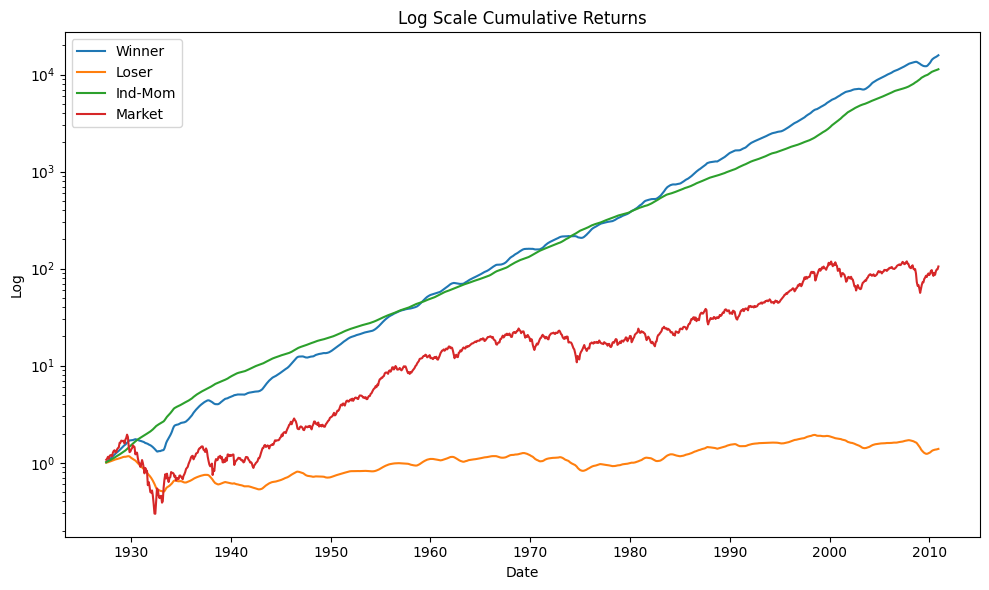

In [409]:
# Cummulative plot
plt.figure(figsize=(10,6))
plt.plot(cumulative_winner, label='Winner')
plt.plot(cumulative_loser, label='Loser')
plt.plot(cumulative_mom, label='Ind-Mom')
plt.plot(cumulative_market, label='Market')
plt.yscale('log')
plt.title('Log Scale Cumulative Returns')
plt.xlabel('Date')
plt.ylabel('Log')
plt.legend()
plt.tight_layout()
plt.show()

In [396]:
# 2.6

ind_mom_2009 = ind_mom[ind_mom.index.year == 2009]
ind_mom_2009

Date
2009-01-01    0.014111
2009-02-01    0.015942
2009-03-01    0.018486
2009-04-01    0.015688
2009-05-01    0.011527
2009-06-01    0.010317
2009-07-01    0.012509
2009-08-01    0.010109
2009-09-01    0.007928
2009-10-01    0.006054
2009-11-01    0.009283
2009-12-01    0.012868
dtype: float64

In [395]:
mkt_2009 = mkt[mkt.index.year == 2009]
mkt_2009

Date
2009-01-01   -0.0775
2009-02-01   -0.1012
2009-03-01    0.0876
2009-04-01    0.1104
2009-05-01    0.0673
2009-06-01   -0.0028
2009-07-01    0.0824
2009-08-01    0.0318
2009-09-01    0.0452
2009-10-01   -0.0284
2009-11-01    0.0574
2009-12-01    0.0292
Name: Mkt-RF, dtype: float64

In [ ]:
# Industry momentum did not do well during Sep-Nov 2009, as well as market. 
# This maybe because 2009 is after the financial crisis, and at the end of 2009, even though momentum strategies 
# start to gainning profit as the economy started to recover, however, market overall still need more time,
# so the return of market is less than return of momentum strategies. 
